A Prebuilt ReAct Agent is a ready-made AI agent that follows the ReAct (Reasoning + Acting) approach.

In [7]:
import os
from getpass import getpass

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langgraph.prebuilt import create_react_agent

load_dotenv()
model = ChatOpenAI(
    model="llama3.2:3b",
    base_url="http://localhost:11434/v1",
    api_key="ollama",
)
tavily_search = TavilySearch(
    max_results=5,
    tavily_api_key=os.getenv("TAVILY_API_KEY") or getpass("Tavily API key: "),
)
tools = [tavily_search]

In [19]:
from langchain_core.tools import tool
from datetime import datetime

@tool
def search_web(query: str):
    """Search the web for current information using a plain-text query."""
    return tavily_search.invoke({"query": query})

@tool
def get_current_datetime():
    """Returns the current date and time."""
    return f" The current date and time is: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"

tools = [search_web, get_current_datetime]
graph = create_react_agent(model=model, tools=tools)

C:\Users\siva.gora\AppData\Local\Temp\ipykernel_19764\3335203712.py:15: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  graph = create_react_agent(model=model, tools=tools)


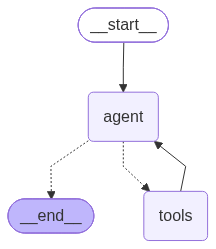

In [10]:
from IPython.display import display, Image

#Visualize an image
display(Image(graph.get_graph().draw_mermaid_png()))


In [11]:
# helper function to render the graph as an image
from IPython.display import display, Image, Markdown

def render_graph(md_string):
    display(Markdown(md_string))

In [16]:
# Helper function to stream the agent's response
def process_stream(stream):
    for state in stream:
        message = state["messages"][-1]
        if isinstance(message, tuple):
            print(message[1])
        else:
            message.pretty_print()
    return message

In [17]:
# helper function to process query
def process_query(query):
    inputs = {"messages": [("user", query)]}
    message = process_stream(graph.stream(inputs, stream_mode="values"))
    render_graph(f"## Answer:\n{message.content}")

In [20]:
process_query("Who won the latest F1 race in Singapore?")

================================ Human Message =================================

Who won the latest F1 race in Singapore?
================================== Ai Message ==================================
Tool Calls:
  search_web (call_b80hqwlc)
 Call ID: call_b80hqwlc
  Args:
    query: latest F1 race Singapore winner
================================= Tool Message =================================
Name: search_web

{"query": "latest F1 race Singapore winner", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.skysports.com/f1/news/13597650/singapore-gp-max-verstappen-wins-event-for-first-time-in-f1-career-ahead-of-charles-leclerc-as-lewis-hamilton-apologises-for-strategy", "title": "Singapore GP: Max Verstappen wins event for first time in F1 career ahead of Charles Leclerc as Lewis Hamilton apologises for strategy | F1 News | Sky Sports", "content": "Nigel Chiu  \n\nSports Journalist @NigelCJourno\n\nMonday 12 October 2026 06:21, UK\n\nPlease u

## Answer:
The winner of the latest F1 race in Singapore is Max Verstappen.

In [21]:
process_query("What is the weather in Hyderabad tomorrow?")

================================ Human Message =================================

What is the weather in Hyderabad tomorrow?
================================== Ai Message ==================================
Tool Calls:
  search_web (call_xpbpidaw)
 Call ID: call_xpbpidaw
  Args:
    query: Hyderabad weather tomorrow
================================= Tool Message =================================
Name: search_web

{"query": "Hyderabad weather tomorrow", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "Weather in Hyderabad", "url": "https://www.weatherapi.com/", "content": "{\"location\": {\"name\": \"Hyderabad\", \"region\": \"Telangana\", \"country\": \"India\", \"localtime\": \"2026-11-18 19:47\"}, \"current\": {\"last_updated\": \"2026-11-18 19:30\", \"temp_c\": 22.9, \"temp_f\": 73.3, \"feelslike_c\": 21.0, \"feelslike_f\": 69.8, \"humidity\": 48, \"wind_kph\": 12.2, \"wind_mph\": 7.6, \"wind_dir\": \"NNE\", \"precip_mm\": 0.0, \"precip_in\": 0.0, \"c

## Answer:
Based on the tool call response, the weather in Hyderabad tomorrow, November 18, 2026, is expected to be partly cloudy with a high of 27°C and a low of 18°C. There is a slight chance of rain.